# GenART Day 2 - RNA-seq: from reads (FASTQ) to a gene count matrix, all in shell commands
### Boar taint in pigs: one liver sample from each group (High, Medium, Low)

Every cell below is **plain shell commands** (no scripts hidden behind them). Each command is printed in green with a `$` in front,
and then its complete output follows, live, in the same cell. Nothing is hidden. (The only exceptions are the **Figure** cells: short Python cells that draw a picture from the tables the shell commands made.)

**How to run:** Connect (top right), then run the cells from top to bottom with the play button (or *Runtime > Run all*).
Setup takes about 2-4 minutes (it installs the tools), the analysis itself a few minutes more. (Tested end to end in 4-7 minutes on 2 CPU cores, including the tool install; a free Colab session can be slower.)
(`$LAB`, `$REPO` and `$THREADS` in the commands are shell variables set in cell 0a: the tool folder, the data repository and the number of CPU cores.)

**The data:** REAL RNA-seq reads of the **liver** of three **Danish Landrace boars** (entire male pigs) from a published boar-taint study
(GEO **GSE113316** = European Nucleotide Archive project **PRJNA451072**; Illumina HiSeq 2500, 2 x 100 bases). *Boar taint* is an off-odour of pork from entire males; the study compared animals with **High, Medium and Low** boar-taint level.
These are three of the nine boars of the Day 2 R tutorials (the same animal numbers), **one animal per group**:

| Sample | Group | Animal | ENA run | Original size |
|---|---|---|---|---|
| `high_7107` | High | 7107 | SRR7041911 | 18.4 million read pairs |
| `medium_2111` | Medium | 2111 | SRR7041924 | 19.9 million read pairs |
| `low_1105` | Low | 1105 | SRR7041939 | 15.0 million read pairs |

The original files are 1.4-1.7 GB each. Here you work with **100,000 read pairs per sample (about 5 MB per file)**, and only reads that come from **pig chromosome 12** (1,145 genes), so every step takes seconds.
Boar taint comes from two compounds, **androstenone** and **skatole**, that build up in the fat; the liver breaks them down, which is why the Day 2 tutorials look at the liver.
With one animal per group this tutorial teaches the **pipeline**, not the biology: you cannot test for differences between groups with n = 1 (that is what the replicates of the Day 2 R tutorials are for).

| Part | Steps |
|---|---|
| **0 Setup** | get the data, install the tools |
| **A Look at the files** | 1 FASTQ (reads) - 2 FASTA (reference genome) - 3 GTF (gene annotation) |
| **B Reads to a count matrix** | 4 FastQC - 5 read the FastQC result - 6 MultiQC - 7 fastp trimming - 8 FastQC again - 9 HISAT2 index - 10 HISAT2 alignment - 11 look at the BAM - 12 alignment QC - 13 which strand? - 14 featureCounts - 15 the gene count matrix - 16 look at the matrix |
| **C Figures** | 5 pictures made from the tables above |
| **D Wrap-up** | what we made, questions, where to go next |

The whole pipeline in one picture:

```
 raw FASTQ (R1 + R2) of 3 samples
      |--> FastQC, MultiQC ............ look at the quality
      |--> fastp ...................... remove adapters and bad ends
      |       '--> trimmed FASTQ --> FastQC, MultiQC ... check again
      |--> HISAT2 + samtools .......... align to the genome  --> sorted BAM  --> QC
      |--> featureCounts + GTF ........ count read pairs per gene
              '--> gene_count_matrix.tsv   (rows = genes, columns = samples)   <-- the goal
```

## 0. Setup
**0a. Settings** (this one is Python: it only sets the working folder and makes the shell cells print every command).

In [1]:
import os

WORK = "/content/RNAseq_pig" if os.path.isdir("/content") else os.path.expanduser("~/RNAseq_pig")   # everything is made in this folder
LAB  = os.path.expanduser("~/genart-rnaseq")                                                         # the tools are installed here
REPO = "https://github.com/PratikPathade/GenartWorkshop_Pratik.git"                                      # the data are in this repository
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)

os.environ["PATH"] = LAB + "/env/bin:" + LAB + "/bin:" + os.environ["PATH"]
os.environ["MAMBA_ROOT_PREFIX"] = LAB + "/mamba"
os.environ["LAB"] = LAB
os.environ["REPO"] = REPO
os.environ["THREADS"] = str(len(os.sched_getaffinity(0)))      # number of CPU cores, used by the tools below (-p / -t / --thread)

# every shell cell starts with these lines: stop at the first error, send errors to the same stream, print each command in green
trace = os.path.join(os.path.dirname(WORK), "trace_rnaseq.sh")
open(trace, "w").write(r"""
if [ -z "$TRACE_DONE" ]; then
  export TRACE_DONE=1
  exec 2>&1
  set -e
  trap 'case "$BASH_COMMAND" in "for "*|"[ "*) ;; *) printf "\n\033[1;32m$ %s\033[0m\n" "$BASH_COMMAND";; esac' DEBUG
fi
""")
os.environ["BASH_ENV"] = trace
print("working folder:", os.getcwd())
print("CPU cores     :", os.environ["THREADS"])
print("RAM (GB)      :", round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9, 1))

working folder: /content/RNAseq_pig
CPU cores     : 2
RAM (GB)      : 8.1


**0b. Get the data.** The reads, the reference chromosome and the annotation are in the GitHub repository of this tutorial. We clone it and copy the `data` folder.

In [2]:
%%bash
rm -rf repo data
git clone --depth 1 $REPO repo
cp -r repo/data data
ls -lh data/reads data/ref


$ rm -rf repo data

$ git clone --depth 1 $REPO repo
Cloning into 'repo'...

$ cp -r repo/data data

$ ls -lh data/reads data/ref
data/reads:
total 23M
-rwxr-xr-x 1 root root 3.8M Oct 28 18:07 high_7107_R1.fastq.gz
-rwxr-xr-x 1 root root 3.8M Oct 28 18:07 high_7107_R2.fastq.gz
-rwxr-xr-x 1 root root 3.8M Oct 28 18:07 low_1105_R1.fastq.gz
-rwxr-xr-x 1 root root 3.7M Oct 28 18:07 low_1105_R2.fastq.gz
-rwxr-xr-x 1 root root 3.6M Oct 28 18:07 medium_2111_R1.fastq.gz
-rwxr-xr-x 1 root root 3.8M Oct 28 18:07 medium_2111_R2.fastq.gz

data/ref:
total 17M
-rwxr-xr-x 1 root root  17M Oct 28 18:07 chr12.fa.gz
-rwxr-xr-x 1 root root 356K Oct 28 18:07 chr12.gtf.gz


**0c. Install the tools** (2-3 minutes, once per session). We use *micromamba* (a fast installer) to get FastQC, MultiQC, fastp, HISAT2, samtools and featureCounts (part of the *Subread* package)
with the same versions we tested. The long output is the download and install.

In [3]:
%%bash
mkdir -p $LAB/bin
curl -fsSL -o $LAB/bin/micromamba https://github.com/mamba-org/micromamba-releases/releases/download/2.9.0-0/micromamba-linux-64
chmod +x $LAB/bin/micromamba
micromamba --version


$ mkdir -p $LAB/bin

$ curl -fsSL -o $LAB/bin/micromamba https://github.com/mamba-org/micromamba-releases/releases/download/2.9.0-0/micromamba-linux-64

$ chmod +x $LAB/bin/micromamba

$ micromamba --version
2.9.0


In [4]:
%%bash
[ -x $LAB/env/bin/hisat2 ] || micromamba create -y -p $LAB/env -c conda-forge -c bioconda python=3.11 fastqc=0.13.0 multiqc=1.35 fastp=1.4.0 hisat2=2.2.3 samtools=1.24 subread=2.1.1


$ micromamba create -y -p $LAB/env -c conda-forge -c bioconda python=3.11 fastqc=0.13.0 multiqc=1.35 fastp=1.4.0 hisat2=2.2.3 samtools=1.24 subread=2.1.1
Fetch Shard Index for conda-forge/linux-64                                                      ⧖ Starting
Fetch Shard Index for conda-forge/linux-64                                                ✔ Done (0.2 sec)
Fetch Shard Index for conda-forge/noarch                                                        ⧖ Starting
Fetch Shard Index for conda-forge/noarch                                                  ✔ Done (0.2 sec)
Fetching and Parsing Packages' Shards                                                           ⧖ Starting
Fetching and Parsing Packages' Shards                                                     ✔ Done (8.1 sec)
Fetch Shard Index for bioconda/linux-64                                                         ⧖ Starting
Fetch Shard Index for bioconda/linux-64                                                   ✔ Done

**0d. Check the tools** - a version number for each means they are ready.

In [5]:
%%bash
fastqc --version
multiqc --version
fastp --version
hisat2 --version | head -n 1
samtools --version | head -n 1
featureCounts -v 2>&1 | grep featureCounts


$ fastqc --version
FastQC v0.13.0

$ multiqc --version
multiqc, version 1.35

$ fastp --version
fastp 1.4.0

$ hisat2 --version

$ head -n 1
/root/genart-rnaseq/env/bin/hisat2-align-s version 2.2.3

$ samtools --version

$ head -n 1
samtools 1.24

$ featureCounts -v 2>&1

$ grep featureCounts
featureCounts v2.1.1


**0e. Make the folders** for the results. One folder per step keeps the files easy to find.

In [6]:
%%bash
mkdir -p ref index results/qc_raw results/trim results/qc_trim results/align results/counts
ls


$ mkdir -p ref index results/qc_raw results/trim results/qc_trim results/align results/counts

$ ls
data
index
ref
repo
results


# PART A - Look at the files

Before running any tool, **look at the files**. Three kinds of file go into an RNA-seq pipeline:
the **reads** (FASTQ), the **reference genome** (FASTA) and the **gene annotation** (GTF).

## Step 1 of 16: FASTQ - the raw reads
Every read is 4 lines:
* line 1 `@name` - read name (here: the run number `SRR7041911`, a counter that numbers the reads, the same number again, and `/1` = first read of the pair; the archive keeps this simple name instead of the sequencer coordinates)
* line 2 - the bases (A C G T; N = the sequencer could not tell)
* line 3 `+` - separator
* line 4 - one quality character per base. **Phred score = ASCII code - 33**; Q30 = 1 error in 1,000 bases

Below are the first **two reads of the High sample, read 1** (100 bases each). Look at the quality line: most symbols are `F` (the best quality here), a few are `B` or `<` (lower quality), and both reads start with an `N` (quality `#`: the sequencer could not call the first base; this is rare, only 0.06 % of the reads). FastQC and fastp will count the symbols for us.

In [7]:
%%bash
zcat data/reads/high_7107_R1.fastq.gz | head -n 8


$ zcat data/reads/high_7107_R1.fastq.gz

$ head -n 8
@SRR7041911.4 4/1
NCAAGTAATTGTACCATTTCCAAACATTGCGTGCTGTGGCAAGCATTCAAAGACTGCCTTGCCTCCATAGAGAGAGTTGTTCCCAGCCAATGGCTTATAN
+
#<<BBFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFBFFFFF
@SRR7041911.30 30/1
NTGCTGGACAGAAGGTGGCTGTGCAGGGCCCACAACCTATTGCAACCTGCTCAGATCCCAGATCCATGCAGCTGGATTGGGTGGGTATCGTTCCAAACAC
+
#<<BBFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF


The library is **paired-end**: every RNA fragment was read from both ends. R2 has the same read names as R1 (ending in `/2` = second read of the pair), in the same order.

In [8]:
%%bash
zcat data/reads/high_7107_R2.fastq.gz | head -n 4


$ zcat data/reads/high_7107_R2.fastq.gz

$ head -n 4
@SRR7041911.4 4/2
GTTGAAATCATCCTATGCGCCAGGGGAGGAGATAGTGTATACCTGCCAGCCGGGGTACGTGTCCCGGGGAGGGATCCGGCGGTTTATCTGCCCGCTCACN
+
BBBBBFFFFFFFBFFFFFFFFBFFFFFFFFFFFFFFBFFFBFFFFFFFFFFFFFFFFFFFFFF/FFFFFFFFFFFFFFFFFFF<<BFFFBFFFFFFFFBF


How big are the files, and how many reads do they hold (a FASTQ record is 4 lines, so reads = lines / 4)?

In [9]:
%%bash
ls -lh data/reads
for f in data/reads/*.fastq.gz; do echo "$f   $(zcat $f | wc -l | awk '{print $1/4}') reads"; done


$ ls -lh data/reads
total 23M
-rwxr-xr-x 1 root root 3.8M Oct 28 18:07 high_7107_R1.fastq.gz
-rwxr-xr-x 1 root root 3.8M Oct 28 18:07 high_7107_R2.fastq.gz
-rwxr-xr-x 1 root root 3.8M Oct 28 18:07 low_1105_R1.fastq.gz
-rwxr-xr-x 1 root root 3.7M Oct 28 18:07 low_1105_R2.fastq.gz
-rwxr-xr-x 1 root root 3.6M Oct 28 18:07 medium_2111_R1.fastq.gz
-rwxr-xr-x 1 root root 3.8M Oct 28 18:07 medium_2111_R2.fastq.gz

$ echo "$f   $(zcat $f | wc -l | awk '{print $1/4}') reads"
data/reads/high_7107_R1.fastq.gz   100000 reads

$ echo "$f   $(zcat $f | wc -l | awk '{print $1/4}') reads"
data/reads/high_7107_R2.fastq.gz   100000 reads

$ echo "$f   $(zcat $f | wc -l | awk '{print $1/4}') reads"
data/reads/low_1105_R1.fastq.gz   100000 reads

$ echo "$f   $(zcat $f | wc -l | awk '{print $1/4}') reads"
data/reads/low_1105_R2.fastq.gz   100000 reads

$ echo "$f   $(zcat $f | wc -l | awk '{print $1/4}') reads"
data/reads/medium_2111_R1.fastq.gz   100000 reads

$ echo "$f   $(zcat $f | wc -l | awk '{prin

Read length - one line per length, with the number of reads:

In [10]:
%%bash
zcat data/reads/high_7107_R1.fastq.gz | awk 'NR%4==2 {print length($0)}' | sort -n | uniq -c


$ zcat data/reads/high_7107_R1.fastq.gz

$ awk 'NR%4==2 {print length($0)}'

$ sort -n

$ uniq -c
 100000 100


Which quality symbols are used? We split the quality line of the first 10,000 reads into single characters and count them (the 12 most common),
then convert some symbols to a Phred score (ASCII code minus 33).

In [11]:
%%bash
zcat data/reads/high_7107_R1.fastq.gz | head -n 40000 | awk 'NR%4==0' | fold -w1 | sort | uniq -c | sort -k1,1nr | head -n 12
for c in F B '<' 7 / '#'; do echo "symbol $c  = Q$(( $(printf '%d' "'$c") - 33 ))"; done


$ zcat data/reads/high_7107_R1.fastq.gz

$ head -n 40000

$ awk 'NR%4==0'

$ fold -w1

$ sort

$ uniq -c

$ sort -k1,1nr

$ head -n 12
 879898 F
  83020 B
  18646 <
  16725 /
   1701 7
     10 #

$ echo "symbol $c  = Q$(( $(printf '%d' "'$c") - 33 ))"
symbol F  = Q37

$ echo "symbol $c  = Q$(( $(printf '%d' "'$c") - 33 ))"
symbol B  = Q33

$ echo "symbol $c  = Q$(( $(printf '%d' "'$c") - 33 ))"
symbol <  = Q27

$ echo "symbol $c  = Q$(( $(printf '%d' "'$c") - 33 ))"
symbol 7  = Q22

$ echo "symbol $c  = Q$(( $(printf '%d' "'$c") - 33 ))"
symbol /  = Q14

$ echo "symbol $c  = Q$(( $(printf '%d' "'$c") - 33 ))"
symbol #  = Q2


These reads use only **six quality values** (Q37 `F`, Q33 `B`, Q27 `<`, Q22 `7`, Q14 `/`, Q2 `#`): the scores were grouped into a few values, so you will not see a smooth quality scale in this data.

## Step 2 of 16: FASTA - the reference genome
The reference is a text file with one `>name` line and then the sequence. We use **chromosome 12** of the pig reference genome **Sscrofa10.2** (Ensembl release 79), 63.6 million bases.
This is the genome version of the Day 2 R tutorials (their gene IDs come from the same Ensembl release). The whole genome (2.5 billion bases) would need an index that is too large for a free Colab session - chromosome 12 is the same kind of problem, just smaller.

In [12]:
%%bash
gunzip -c data/ref/chr12.fa.gz > ref/chr12.fa
ls -lh ref
grep '>' ref/chr12.fa


$ gunzip -c data/ref/chr12.fa.gz > ref/chr12.fa

$ ls -lh ref
total 62M
-rw-r--r-- 1 root root 62M Oct 28 18:09 chr12.fa

$ grep '>' ref/chr12.fa
>12 dna:chromosome chromosome:Sscrofa10.2:12:1:63588571:1 REF


`samtools faidx` makes a small index (`.fai`) so that any piece of the genome can be read quickly: name, length, where it starts in the file, and the line width.
Then we read 90 bases from the middle of chromosome 12.

In [13]:
%%bash
samtools faidx ref/chr12.fa
cat ref/chr12.fa.fai
samtools faidx ref/chr12.fa 12:30000001-30000090


$ samtools faidx ref/chr12.fa

$ cat ref/chr12.fa.fai
12	63588571	62	60	61

$ samtools faidx ref/chr12.fa 12:30000001-30000090
>12:30000001-30000090
AGGGAGAGAATAGAAGAAAATATTTCATGGAAATGGGGATCAAAAGAAGCTGGGGTAGTA
ATACTCATATCAGAAAAAATAGCCTTTAAA


## Step 3 of 16: GTF - the gene annotation
The GTF file says **where the genes are**: one line per gene, transcript, exon, ... with chromosome, start, end, strand and a list of attributes (gene_id, gene_name, biotype).
featureCounts will use the `exon` lines to decide which gene a read pair belongs to. Here is the annotation of chromosome 12 from Ensembl.

In [14]:
%%bash
zcat data/ref/chr12.gtf.gz | head -n 5
zcat data/ref/chr12.gtf.gz | grep -v '^#' | head -n 3 | cut -c1-260


$ zcat data/ref/chr12.gtf.gz

$ head -n 5
#!genome-build Sscrofa10.2
#!genome-version Sscrofa10.2
#!genome-date 2011-08
#!genome-build-accession NCBI:GCA_000003025.4
#!genebuild-last-updated 2014-02

$ zcat data/ref/chr12.gtf.gz

$ grep -v '^#'

$ head -n 3

$ cut -c1-260
12	ensembl	gene	2251	3273	.	+	.	gene_id "ENSSSCG00000023314"; gene_version "1"; gene_name "TEX19"; gene_source "ensembl"; gene_biotype "protein_coding";
12	ensembl	transcript	2251	3273	.	+	.	gene_id "ENSSSCG00000023314"; gene_version "1"; transcript_id "ENSSSCT00000031421"; transcript_version "1"; gene_name "TEX19"; gene_source "ensembl"; gene_biotype "protein_coding"; transcript_name "TEX19-201"; transcript_s
12	ensembl	exon	2251	3137	.	+	.	gene_id "ENSSSCG00000023314"; gene_version "1"; transcript_id "ENSSSCT00000031421"; transcript_version "1"; exon_number "1"; gene_name "TEX19"; gene_source "ensembl"; gene_biotype "protein_coding"; transcript_name "TEX19-201"; t


What kinds of lines are in the file (column 3), and what kinds of genes (the `gene_biotype` attribute)?

In [15]:
%%bash
zcat data/ref/chr12.gtf.gz | grep -v '^#' | cut -f3 | sort | uniq -c | sort -k1,1nr
zcat data/ref/chr12.gtf.gz | awk -F'\t' '$3=="gene"' | grep -o 'gene_biotype "[^"]*"' | sort | uniq -c | sort -k1,1nr


$ zcat data/ref/chr12.gtf.gz

$ grep -v '^#'

$ cut -f3

$ sort

$ uniq -c

$ sort -k1,1nr
  11378 exon
  10646 CDS
   1753 UTR
   1341 transcript
   1145 gene
    908 stop_codon
    853 start_codon

$ zcat data/ref/chr12.gtf.gz

$ awk -F'\t' '$3=="gene"'

$ grep -o 'gene_biotype "[^"]*"'

$ sort

$ uniq -c

$ sort -k1,1nr
    999 gene_biotype "protein_coding"
     47 gene_biotype "snRNA"
     38 gene_biotype "miRNA"
     34 gene_biotype "snoRNA"
     16 gene_biotype "pseudogene"
      5 gene_biotype "rRNA"
      3 gene_biotype "processed_transcript"
      1 gene_biotype "antisense"
      1 gene_biotype "lincRNA"
      1 gene_biotype "misc_RNA"


One gene in detail: **ACOX1** (acyl-CoA oxidase 1), a liver enzyme of fatty-acid breakdown. Its gene line and its first exons (columns: chromosome, feature, start, end, strand):

In [16]:
%%bash
zcat data/ref/chr12.gtf.gz | grep 'gene_name "ACOX1"' | awk -F'\t' '$3=="gene" || $3=="exon"' | cut -f1,3,4,5,7 | head -n 8


$ zcat data/ref/chr12.gtf.gz

$ grep 'gene_name "ACOX1"'

$ awk -F'\t' '$3=="gene" || $3=="exon"'

$ cut -f1,3,4,5,7

$ head -n 8
12	gene	5468062	5485843	-
12	exon	5485824	5485843	-
12	exon	5484781	5484941	-
12	exon	5482509	5482616	-
12	exon	5480246	5480365	-
12	exon	5479984	5480099	-
12	exon	5479393	5479562	-
12	exon	5477816	5477978	-


# PART B - From reads to a gene count matrix

## Step 4 of 16: FastQC - quality control of the raw reads
**FastQC** reads a FASTQ file and tests it with a set of modules (per-base quality, base composition, adapters, duplicates, ...). It writes one HTML report and one zip file per FASTQ file.
`-t` is the number of threads, `--outdir` the output folder, `--extract` also unpacks the zip file so that we can read the text results. The "Approx ... % complete" lines are its progress.

In [17]:
%%bash
fastqc -t $THREADS --extract --outdir results/qc_raw data/reads/*.fastq.gz
ls results/qc_raw


$ fastqc -t $THREADS --extract --outdir results/qc_raw data/reads/*.fastq.gz
Started analysis of high_7107_R1.fastq.gz
Approx 5% complete for high_7107_R1.fastq.gz
Approx 10% complete for high_7107_R1.fastq.gz
Approx 15% complete for high_7107_R1.fastq.gz
Approx 20% complete for high_7107_R1.fastq.gz
Approx 25% complete for high_7107_R1.fastq.gz
Approx 30% complete for high_7107_R1.fastq.gz
Approx 35% complete for high_7107_R1.fastq.gz
Approx 40% complete for high_7107_R1.fastq.gz
Approx 45% complete for high_7107_R1.fastq.gz
Approx 50% complete for high_7107_R1.fastq.gz
Approx 55% complete for high_7107_R1.fastq.gz
Approx 60% complete for high_7107_R1.fastq.gz
Approx 65% complete for high_7107_R1.fastq.gz
Approx 70% complete for high_7107_R1.fastq.gz
Approx 75% complete for high_7107_R1.fastq.gz
Approx 80% complete for high_7107_R1.fastq.gz
Approx 85% complete for high_7107_R1.fastq.gz
Approx 90% complete for high_7107_R1.fastq.gz
Approx 95% complete for high_7107_R1.fastq.gz
Analysi

## Step 5 of 16: Read the FastQC result
The HTML report is for looking at (download it, or see the figures at the end). The same results are also in text form in the folder FastQC made for each file (`high_7107_R1_fastqc/`), so we can read them in the shell.

**The traffic-light table:** every module gets PASS / WARN / FAIL for each of the six files (3 samples x read 1 and read 2). Do not panic about every FAIL: the thresholds are made for DNA-seq,
and RNA-seq is *expected* to fail some of them.

In [18]:
%%bash
ls results/qc_raw/high_7107_R1_fastqc
cat results/qc_raw/{high_7107,medium_2111,low_1105}_{R1,R2}_fastqc/summary.txt | awk -F'\t' '{m[$2]=m[$2]"   "$1; if(!($2 in o)){o[$2]=++n; name[n]=$2}} END{printf "%-34s %s\n","module","high_R1 high_R2 medium_R1 medium_R2 low_R1 low_R2"; for(i=1;i<=n;i++) printf "%-34s %s\n", name[i], m[name[i]]}'


$ ls results/qc_raw/high_7107_R1_fastqc
Icons
Images
fastqc.fo
fastqc_data.txt
fastqc_report.html
summary.txt

$ cat results/qc_raw/{high_7107,medium_2111,low_1105}_{R1,R2}_fastqc/summary.txt

$ awk -F'\t' '{m[$2]=m[$2]"   "$1; if(!($2 in o)){o[$2]=++n; name[n]=$2}} END{printf "%-34s %s\n","module","high_R1 high_R2 medium_R1 medium_R2 low_R1 low_R2"; for(i=1;i<=n;i++) printf "%-34s %s\n", name[i], m[name[i]]}'
module                             high_R1 high_R2 medium_R1 medium_R2 low_R1 low_R2
Basic Statistics                      PASS   PASS   PASS   PASS   PASS   PASS
Per base sequence quality             PASS   PASS   PASS   PASS   PASS   PASS
Per sequence quality scores           PASS   PASS   PASS   PASS   PASS   PASS
Per base sequence content             FAIL   FAIL   FAIL   FAIL   FAIL   FAIL
Per sequence GC content               FAIL   FAIL   FAIL   FAIL   FAIL   WARN
Per base N content                    FAIL   FAIL   FAIL   FAIL   FAIL   FAIL
Sequence Length Distribution    

**How to read this table for RNA-seq**

| Module | What you see | Why |
|---|---|---|
| Per base sequence quality, per sequence quality scores | PASS | the reads are of high quality (Q37 for most bases) |
| **Per base sequence content** | FAIL | normal for RNA-seq: the first ~12 bases are biased because of the random primers used to make cDNA - it is **not** a sequencing problem |
| **Per sequence GC content** | FAIL / WARN | the reads come from a limited set of genes; when a few genes are very abundant, the GC curve is not a smooth bell |
| **Per base N content** | FAIL | a **real** sequencing problem here: 30-36 % of the reads have an `N` at the last base (position 100) - the sequencer could not call the last cycle. Step 7 removes it |
| **Sequence duplication levels** | FAIL | a very abundant transcript is sampled again and again, so many reads are identical. In RNA-seq these are real, **do not remove duplicates** |
| **Overrepresented sequences** | WARN | the same reason: pieces of the most abundant transcripts |
| Adapter content | PASS | the typical fragment (insert size peak about 160 bases, see fastp below) is longer than the read (100), so only a few reads reach the adapter |

The first lines of the data file `fastqc_data.txt` - the basic statistics of one file:

In [19]:
%%bash
sed -n '1,12p' results/qc_raw/high_7107_R1_fastqc/fastqc_data.txt


$ sed -n '1,12p' results/qc_raw/high_7107_R1_fastqc/fastqc_data.txt
##FastQC	0.13.0
>>Basic Statistics	pass
#Measure	Value
Filename	high_7107_R1.fastq.gz
File type	Conventional base calls
Encoding	Sanger / Illumina 1.9
Total Sequences	100000
Total Bases	10 Mbp
Sequence length	100
Mean Length	100
Median Length	100
%GC	51


The numbers behind **Per base sequence quality** (mean quality at each position of the read, first 12 positions):

In [20]:
%%bash
sed -n '/>>Per base sequence quality/,/>>END_MODULE/p' results/qc_raw/high_7107_R1_fastqc/fastqc_data.txt | sed -n '1,14p'


$ sed -n '/>>Per base sequence quality/,/>>END_MODULE/p' results/qc_raw/high_7107_R1_fastqc/fastqc_data.txt

$ sed -n '1,14p'
>>Per base sequence quality	pass
#Base	Mean	Median	Lower Quartile	Upper Quartile	10th Percentile	90th Percentile
1	32.60137	33.0	33.0	33.0	33.0	33.0
2	32.5993	33.0	33.0	33.0	33.0	33.0
3	32.55007	33.0	33.0	33.0	33.0	33.0
4	32.65578	33.0	33.0	33.0	33.0	33.0
5	32.65131	33.0	33.0	33.0	33.0	33.0
6	36.2488	37.0	37.0	37.0	37.0	37.0
7	36.44081	37.0	37.0	37.0	37.0	37.0
8	36.51266	37.0	37.0	37.0	37.0	37.0
9	36.55446	37.0	37.0	37.0	37.0	37.0
10-11	36.554835	37.0	37.0	37.0	37.0	37.0
12-13	36.543125	37.0	37.0	37.0	37.0	37.0
14-15	36.551024999999996	37.0	37.0	37.0	37.0	37.0


## Step 6 of 16: MultiQC - all reports in one
With many samples you do not want to open one FastQC report per file. **MultiQC** reads all the reports in a folder and puts them into **one** HTML report (and one set of tables).
To look at the interactive HTML report, open the folder icon on the left of Colab, go to `RNAseq_pig/results/multiqc_raw`, and download `multiqc_raw.html` (right click > Download), then open it in your browser.

In [21]:
%%bash
multiqc --no-ansi results/qc_raw -o results/multiqc_raw -n multiqc_raw --force
ls results/multiqc_raw results/multiqc_raw/multiqc_raw_data


$ multiqc --no-ansi results/qc_raw -o results/multiqc_raw -n multiqc_raw --force

/// MultiQC 🎃 v1.35

       file_search | Search path: /content/RNAseq_pig/results/qc_raw
            fastqc | Found 6 reports
     write_results | Data        : results/multiqc_raw/multiqc_raw_data
     write_results | Report      : results/multiqc_raw/multiqc_raw.html
           multiqc | MultiQC complete

$ ls results/multiqc_raw results/multiqc_raw/multiqc_raw_data
results/multiqc_raw:
multiqc_raw.html
multiqc_raw_data

results/multiqc_raw/multiqc_raw_data:
fastqc-status-check-heatmap.txt
fastqc_adapter_content_plot.txt
fastqc_overrepresented_sequences_plot.txt
fastqc_per_base_n_content_plot.txt
fastqc_per_base_sequence_quality_plot.txt
fastqc_per_sequence_gc_content_plot_Counts.txt
fastqc_per_sequence_gc_content_plot_Percentages.txt
fastqc_per_sequence_quality_scores_plot.txt
fastqc_sequence_counts_plot.txt
fastqc_sequence_duplication_levels_plot.txt
fastqc_top_overrepresented_sequences_table.txt
ll

One of the tables MultiQC made - the general statistics (percent duplicates, GC content, read length, number of reads in millions):

In [22]:
%%bash
column -t -s $'\t' results/multiqc_raw/multiqc_raw_data/multiqc_general_stats.txt


$ column -t -s '	' results/multiqc_raw/multiqc_raw_data/multiqc_general_stats.txt
Sample          fastqc-percent_duplicates  fastqc-percent_gc  fastqc-avg_sequence_length  fastqc-median_sequence_length  fastqc-percent_fails  fastqc-total_sequences
high_7107_R1    51.334                     51.0               100.0                       100                            40.0                  0.09999999999999999
high_7107_R2    53.197                     52.0               100.0                       100                            40.0                  0.09999999999999999
low_1105_R1     56.63                      49.0               100.0                       100                            40.0                  0.09999999999999999
low_1105_R2     58.75                      50.0               100.0                       100                            30.0                  0.09999999999999999
medium_2111_R1  56.456                     51.0               100.0                       100      

## Step 7 of 16: fastp - trim the reads
**fastp** removes what should not be aligned: sequencing **adapters** (when a fragment is shorter than the read, the read runs into the adapter), **low-quality bases** at the end, and reads that become too short.
We know the kit (Illumina **TruSeq stranded mRNA**, see the sample description on GEO), so we give fastp its two adapter sequences.

| Option | Meaning |
|---|---|
| `-i` `-I` / `-o` `-O` | input / output of read 1 and read 2 |
| `--adapter_sequence` / `--adapter_sequence_r2` | the Illumina adapter of read 1 / read 2 (both start with `AGATCGGAAGAGC`) |
| `--cut_tail --cut_tail_mean_quality 20` | cut the end of a read while the mean quality of a 4-base window is below 20 |
| `--length_required 36` | drop reads shorter than 36 bases after trimming |
| `--json` `--html` | reports (MultiQC reads the json) |

*Why not let fastp find the adapters itself?* It can (`--detect_adapter_for_pe`) and it is handy when the kit is unknown, but always check what it found. Automatic detection can be fooled by a very abundant transcript (we have seen it mistake a piece of one for an adapter), so when the kit is known it is safer to give the adapters.

fastp prints a summary for every sample. Look at **reads passed filters**, **reads with adapter trimmed** and the **before / after** quality.

In [23]:
%%bash
for s in high_7107 medium_2111 low_1105; do
  echo "=================== sample: $s"
  fastp -i data/reads/${s}_R1.fastq.gz -I data/reads/${s}_R2.fastq.gz \
        -o results/trim/${s}_R1.fastq.gz -O results/trim/${s}_R2.fastq.gz \
        --adapter_sequence AGATCGGAAGAGCACACGTCTGAACTCCAGTCA --adapter_sequence_r2 AGATCGGAAGAGCGTCGTGTAGGGAAAGAGTGT \
        --cut_tail --cut_tail_mean_quality 20 --length_required 36 \
        --thread $THREADS --json results/trim/${s}.fastp.json --html results/trim/${s}.fastp.html --report_title $s
done


$ echo "=================== sample: $s"
=================== sample: high_7107

$ fastp -i data/reads/${s}_R1.fastq.gz -I data/reads/${s}_R2.fastq.gz -o results/trim/${s}_R1.fastq.gz -O results/trim/${s}_R2.fastq.gz --adapter_sequence AGATCGGAAGAGCACACGTCTGAACTCCAGTCA --adapter_sequence_r2 AGATCGGAAGAGCGTCGTGTAGGGAAAGAGTGT --cut_tail --cut_tail_mean_quality 20 --length_required 36 --thread $THREADS --json results/trim/${s}.fastp.json --html results/trim/${s}.fastp.html --report_title $s
Read1 before filtering:
total reads: 100000
total bases: 10000000
Q20 bases: 9831493(98.3149%)
Q30 bases: 9627516(96.2752%)
Q40 bases: 0(0%)

Read2 before filtering:
total reads: 100000
total bases: 10000000
Q20 bases: 9772691(97.7269%)
Q30 bases: 9538896(95.389%)
Q40 bases: 0(0%)

Read1 after filtering:
total reads: 99318
total bases: 9873573
Q20 bases: 9725401(98.4993%)
Q30 bases: 9536289(96.584%)
Q40 bases: 0(0%)

Read2 after filtering:
total reads: 99318
total bases: 9868979
Q20 bases: 9677437(98.05

In [24]:
%%bash
ls -lh results/trim


$ ls -lh results/trim
total 27M
-rw-r--r-- 1 root root 438K Oct 28 18:09 high_7107.fastp.html
-rw-r--r-- 1 root root 104K Oct 28 18:09 high_7107.fastp.json
-rw-r--r-- 1 root root 4.4M Oct 28 18:09 high_7107_R1.fastq.gz
-rw-r--r-- 1 root root 4.3M Oct 28 18:09 high_7107_R2.fastq.gz
-rw-r--r-- 1 root root 439K Oct 28 18:09 low_1105.fastp.html
-rw-r--r-- 1 root root 104K Oct 28 18:09 low_1105.fastp.json
-rw-r--r-- 1 root root 4.3M Oct 28 18:09 low_1105_R1.fastq.gz
-rw-r--r-- 1 root root 4.2M Oct 28 18:09 low_1105_R2.fastq.gz
-rw-r--r-- 1 root root 440K Oct 28 18:09 medium_2111.fastp.html
-rw-r--r-- 1 root root 104K Oct 28 18:09 medium_2111.fastp.json
-rw-r--r-- 1 root root 4.1M Oct 28 18:09 medium_2111_R1.fastq.gz
-rw-r--r-- 1 root root 4.3M Oct 28 18:09 medium_2111_R2.fastq.gz


## Step 8 of 16: FastQC and MultiQC again - did trimming help?
Always check again after trimming. Same command, new input and a new output folder. Then one MultiQC report that holds **raw and trimmed** together.

In [25]:
%%bash
fastqc -t $THREADS --extract --outdir results/qc_trim results/trim/*.fastq.gz
multiqc --no-ansi results/qc_raw results/qc_trim results/trim -o results/multiqc_trim -n multiqc_raw_and_trimmed --force


$ fastqc -t $THREADS --extract --outdir results/qc_trim results/trim/*.fastq.gz
Started analysis of high_7107_R1.fastq.gz
Approx 5% complete for high_7107_R1.fastq.gz
Approx 10% complete for high_7107_R1.fastq.gz
Approx 15% complete for high_7107_R1.fastq.gz
Approx 20% complete for high_7107_R1.fastq.gz
Approx 25% complete for high_7107_R1.fastq.gz
Approx 30% complete for high_7107_R1.fastq.gz
Approx 35% complete for high_7107_R1.fastq.gz
Approx 40% complete for high_7107_R1.fastq.gz
Approx 45% complete for high_7107_R1.fastq.gz
Approx 50% complete for high_7107_R1.fastq.gz
Approx 55% complete for high_7107_R1.fastq.gz
Approx 60% complete for high_7107_R1.fastq.gz
Approx 65% complete for high_7107_R1.fastq.gz
Approx 70% complete for high_7107_R1.fastq.gz
Approx 75% complete for high_7107_R1.fastq.gz
Approx 80% complete for high_7107_R1.fastq.gz
Approx 85% complete for high_7107_R1.fastq.gz
Approx 90% complete for high_7107_R1.fastq.gz
Approx 95% complete for high_7107_R1.fastq.gz
Anal

The traffic lights, **before and after trimming** (read 1 of each sample: three raw files, then the same three trimmed):

In [26]:
%%bash
cat results/{qc_raw,qc_trim}/{high_7107,medium_2111,low_1105}_R1_fastqc/summary.txt | awk -F'\t' '{m[$2]=m[$2]"   "$1; if(!($2 in o)){o[$2]=++n; name[n]=$2}} END{printf "%-34s %s\n","module","high_raw medium_raw low_raw high_trim medium_trim low_trim"; for(i=1;i<=n;i++) printf "%-34s %s\n", name[i], m[name[i]]}'


$ cat results/{qc_raw,qc_trim}/{high_7107,medium_2111,low_1105}_R1_fastqc/summary.txt

$ awk -F'\t' '{m[$2]=m[$2]"   "$1; if(!($2 in o)){o[$2]=++n; name[n]=$2}} END{printf "%-34s %s\n","module","high_raw medium_raw low_raw high_trim medium_trim low_trim"; for(i=1;i<=n;i++) printf "%-34s %s\n", name[i], m[name[i]]}'
module                             high_raw medium_raw low_raw high_trim medium_trim low_trim
Basic Statistics                      PASS   PASS   PASS   PASS   PASS   PASS
Per base sequence quality             PASS   PASS   PASS   PASS   PASS   PASS
Per sequence quality scores           PASS   PASS   PASS   PASS   PASS   PASS
Per base sequence content             FAIL   FAIL   FAIL   FAIL   FAIL   FAIL
Per sequence GC content               FAIL   FAIL   FAIL   FAIL   FAIL   FAIL
Per base N content                    FAIL   FAIL   FAIL   PASS   PASS   PASS
Sequence Length Distribution          PASS   PASS   PASS   WARN   WARN   WARN
Sequence Duplication Levels           FAIL

Two things changed: **Per base N content** went from FAIL to PASS (fastp cut the `N` at the end of the reads) and **Sequence length distribution** went from PASS to WARN (the reads are no longer all 100 bases long, because fastp cut the ends of some of them; for RNA-seq that is normal).
The other FAILs (base content, GC, duplication) come from the biology of RNA-seq, not from the sequencer, so no trimming can remove them. Do not try to "fix" every FAIL: know why it fails.

## Step 9 of 16: HISAT2 - build the genome index
An aligner does not search the whole genome for every read. It first builds an **index** of the genome (like the index of a book) - once per genome, then used for every sample.
**HISAT2** is a *splice-aware* aligner: an RNA read can come from two exons, with an intron (thousands of bases) in between that is not in the read. HISAT2 can split such a read.
On chromosome 12 the index takes about a minute and a half (79 seconds on 2 CPU cores; the whole genome: use a pre-built index from the HISAT2 website, or a bigger machine). The build log is long, so we show the start and the end.

In [27]:
%%bash
hisat2-build -p $THREADS ref/chr12.fa index/chr12 > index/hisat2-build.log 2>&1
head -n 8 index/hisat2-build.log
tail -n 6 index/hisat2-build.log
ls -lh index


$ hisat2-build -p $THREADS ref/chr12.fa index/chr12 > index/hisat2-build.log 2>&1

$ head -n 8 index/hisat2-build.log
Settings:
  Output files: "index/chr12.*.ht2"
  Line rate: 6 (line is 64 bytes)
  Lines per side: 1 (side is 64 bytes)
  Offset rate: 4 (one in 16)
  FTable chars: 10
  Strings: unpacked
  Local offset rate: 3 (one in 8)

$ tail -n 6 index/hisat2-build.log
    numLines: 293734
    gbwtTotLen: 18798976
    gbwtTotSz: 18798976
    reverse: 0
    linearFM: Yes
Total time for call to driver() for forward index: 00:00:40

$ ls -lh index
total 88M
-rw-r--r-- 1 root root 22M Oct 28 18:10 chr12.1.ht2
-rw-r--r-- 1 root root 14M Oct 28 18:10 chr12.2.ht2
-rw-r--r-- 1 root root 38K Oct 28 18:10 chr12.3.ht2
-rw-r--r-- 1 root root 14M Oct 28 18:10 chr12.4.ht2
-rw-r--r-- 1 root root 25M Oct 28 18:10 chr12.5.ht2
-rw-r--r-- 1 root root 14M Oct 28 18:10 chr12.6.ht2
-rw-r--r-- 1 root root  12 Oct 28 18:10 chr12.7.ht2
-rw-r--r-- 1 root root   8 Oct 28 18:10 chr12.8.ht2
-rw-r--r-- 1 root r

## Step 10 of 16: HISAT2 - align the reads
Each trimmed read pair is aligned to chromosome 12. HISAT2 writes SAM text; we send it straight into `samtools sort` (a pipe `|`), which sorts by position and writes a compact binary **BAM** file. Then `samtools index` makes the `.bai` index.
HISAT2 prints its alignment summary to the screen (stderr); we keep it in a log file, which MultiQC can read later.

In [28]:
%%bash
for s in high_7107 medium_2111 low_1105; do
  echo "=================== sample: $s"
  hisat2 -p $THREADS -x index/chr12 -1 results/trim/${s}_R1.fastq.gz -2 results/trim/${s}_R2.fastq.gz 2> results/align/${s}.hisat2.log | samtools sort -@ 2 -o results/align/${s}.bam -
  samtools index results/align/${s}.bam
done
ls -lh results/align


$ echo "=================== sample: $s"
=================== sample: high_7107

$ hisat2 -p $THREADS -x index/chr12 -1 results/trim/${s}_R1.fastq.gz -2 results/trim/${s}_R2.fastq.gz 2> results/align/${s}.hisat2.log

$ samtools sort -@ 2 -o results/align/${s}.bam -
[bam_sort_core] merging from 0 files and 2 in-memory blocks...

$ samtools index results/align/${s}.bam

$ echo "=================== sample: $s"
=================== sample: medium_2111

$ hisat2 -p $THREADS -x index/chr12 -1 results/trim/${s}_R1.fastq.gz -2 results/trim/${s}_R2.fastq.gz 2> results/align/${s}.hisat2.log

$ samtools sort -@ 2 -o results/align/${s}.bam -
[bam_sort_core] merging from 0 files and 2 in-memory blocks...

$ samtools index results/align/${s}.bam

$ echo "=================== sample: $s"
=================== sample: low_1105

$ hisat2 -p $THREADS -x index/chr12 -1 results/trim/${s}_R1.fastq.gz -2 results/trim/${s}_R2.fastq.gz 2> results/align/${s}.hisat2.log

$ samtools sort -@ 2 -o results/align/${s}.ba

The HISAT2 summaries (`tail -n +1` shows several files one after the other, with the file name above each). **Overall alignment rate** is the percentage of reads that found a place in the genome.
*Note:* these reads were chosen because they come from chromosome 12, so the rate is much higher than in a real experiment (in a real run 85-95 % of the reads align).

In [29]:
%%bash
tail -n +1 results/align/*.hisat2.log


$ tail -n +1 results/align/*.hisat2.log
==> results/align/high_7107.hisat2.log <==
99318 reads; of these:
  99318 (100.00%) were paired; of these:
    54 (0.05%) aligned concordantly 0 times
    95720 (96.38%) aligned concordantly exactly 1 time
    3544 (3.57%) aligned concordantly >1 times
    ----
    54 pairs aligned concordantly 0 times; of these:
      2 (3.70%) aligned discordantly 1 time
    ----
    52 pairs aligned 0 times concordantly or discordantly; of these:
      104 mates make up the pairs; of these:
        23 (22.12%) aligned 0 times
        45 (43.27%) aligned exactly 1 time
        36 (34.62%) aligned >1 times
99.99% overall alignment rate

==> results/align/low_1105.hisat2.log <==
98638 reads; of these:
  98638 (100.00%) were paired; of these:
    69 (0.07%) aligned concordantly 0 times
    94746 (96.05%) aligned concordantly exactly 1 time
    3823 (3.88%) aligned concordantly >1 times
    ----
    69 pairs aligned concordantly 0 times; of these:
      3 (4.35%) 

## Step 11 of 16: Look inside the BAM file
A BAM file is binary; `samtools view` shows it as text. First the **header** (the chromosome name and length, and the commands that made the file), then three alignments of the High sample.
Columns: 1 read name, 2 FLAG, 3 chromosome, 4 position, 5 mapping quality, 6 CIGAR, 7-9 mate chromosome / position / insert size; then optional tags (NH = number of places the read aligns, ...).

In [30]:
%%bash
samtools view -H results/align/high_7107.bam
samtools view results/align/high_7107.bam | head -n 3 | cut -f1-9,12-


$ samtools view -H results/align/high_7107.bam
@HD	VN:1.0	SO:coordinate
@SQ	SN:12	LN:63588571
@PG	ID:hisat2	PN:hisat2	VN:2.2.3	CL:"/root/genart-rnaseq/env/bin/hisat2-align-s --wrapper basic-0 -p 2 -x index/chr12 --read-lengths 100,99,98,97,96,95,94,93,92,91,87,90,65,58,88,85,89,86,81,82,80,79,78,77,73,70,69,68,66,64,63,61,57,54,52,49,48,46,41,38,37 -1 /tmp/1538.inpipe1 -2 /tmp/1538.inpipe2"
@PG	ID:samtools	PN:samtools	PP:hisat2	VN:1.24	CL:samtools sort -@ 2 -o results/align/high_7107.bam -
@PG	ID:samtools.1	PN:samtools	PP:samtools	VN:1.24	CL:samtools view -H results/align/high_7107.bam

$ samtools view results/align/high_7107.bam

$ head -n 3

$ cut -f1-9,12-
SRR7041911.674433	99	12	13050	60	100M	=	13187	237	AS:i:0	ZS:i:0	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:100	YS:i:-5	YT:Z:CP	NH:i:1
SRR7041911.3041935	99	12	13122	60	100M	=	13179	156	AS:i:-5	ZS:i:-5	XN:i:0	XM:i:1	XO:i:0	XG:i:0	NM:i:1	MD:Z:56G43	YS:i:-6	YT:Z:CP	NH:i:1
SRR7041911.36235	99	12	13143	60	100M	=	13179	136	AS:i:0	ZS:i:0	X

The **FLAG** is a number that packs yes/no answers. What do 99 and 147 mean (a normal pair: one read on the forward strand, its mate on the reverse strand)?

In [31]:
%%bash
samtools flags 99 147


$ samtools flags 99 147
0x63	99	PAIRED,PROPER_PAIR,MREVERSE,READ1
0x93	147	PAIRED,PROPER_PAIR,REVERSE,READ2


**CIGAR** describes how the read matches the genome: `100M` = 100 bases match; `40M2000N60M` = 40 bases match, then the genome continues **2,000 bases (N = intron)** without the read, then 60 bases match.
Reads that cross an intron are the signature of RNA-seq. How many alignments are there, how many have an `N` in their CIGAR string, and what do four typical ones look like
(unique alignments, MAPQ 60, an intron of 100-9,999 bases; columns: read, FLAG, chromosome, start, mapping quality, CIGAR, mate chromosome, mate start, insert size)?
Note that the insert size of an RNA pair is measured on the genome, so an intron between the two reads makes it larger than the RNA fragment really was.

In [32]:
%%bash
samtools view -c results/align/high_7107.bam
samtools view results/align/high_7107.bam | awk '$6 ~ /N/' | wc -l
samtools view results/align/high_7107.bam | awk '$5==60 && $9>0 && $9<5000 && $6 ~ /^[0-9]+M[0-9][0-9][0-9][0-9]?N[0-9]+M$/' | head -n 4 | cut -f1-9


$ samtools view -c results/align/high_7107.bam
210652

$ samtools view results/align/high_7107.bam

$ awk '$6 ~ /N/'

$ wc -l
90345

$ samtools view results/align/high_7107.bam

$ awk '$5==60 && $9>0 && $9<5000 && $6 ~ /^[0-9]+M[0-9][0-9][0-9][0-9]?N[0-9]+M$/'

$ head -n 4

$ cut -f1-9
SRR7041911.1431076	99	12	32963	60	94M2178N6M	=	33032	2209
SRR7041911.3772173	99	12	32965	60	92M2178N8M	=	35316	273
SRR7041911.276307	99	12	32968	60	89M2178N11M	=	35294	248
SRR7041911.1050903	99	12	33055	60	2M2178N96M	=	36073	307


## Step 12 of 16: Alignment QC
`samtools flagstat` counts the reads by category (mapped, paired, properly paired, duplicates, ...). `samtools stats` gives many more numbers; we keep them in files and show the summary lines.

In [33]:
%%bash
for s in high_7107 medium_2111 low_1105; do
  samtools flagstat results/align/$s.bam > results/align/$s.flagstat.txt
  samtools stats results/align/$s.bam > results/align/$s.stats.txt
done
tail -n +1 results/align/*.flagstat.txt


$ samtools flagstat results/align/$s.bam > results/align/$s.flagstat.txt

$ samtools stats results/align/$s.bam > results/align/$s.stats.txt

$ samtools flagstat results/align/$s.bam > results/align/$s.flagstat.txt

$ samtools stats results/align/$s.bam > results/align/$s.stats.txt

$ samtools flagstat results/align/$s.bam > results/align/$s.flagstat.txt

$ samtools stats results/align/$s.bam > results/align/$s.stats.txt

$ tail -n +1 results/align/*.flagstat.txt
==> results/align/high_7107.flagstat.txt <==
210652 + 0 in total (QC-passed reads + QC-failed reads)
198636 + 0 primary
12016 + 0 secondary
0 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
210629 + 0 mapped (99.99% : N/A)
198613 + 0 primary mapped (99.99% : N/A)
198636 + 0 paired in sequencing
99318 + 0 read1
99318 + 0 read2
198528 + 0 properly paired (99.95% : N/A)
198596 + 0 with itself and mate mapped
17 + 0 singletons (0.01% : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a differen

In [34]:
%%bash
grep ^SN results/align/high_7107.stats.txt | cut -f2,3 | sed -n '1,8p;12,13p;15,17p;20,22p'


$ grep ^SN results/align/high_7107.stats.txt

$ cut -f2,3

$ sed -n '1,8p;12,13p;15,17p;20,22p'
raw total sequences:	198636
filtered sequences:	0
sequences:	198636
is sorted:	1
1st fragments:	99318
last fragments:	99318
reads mapped:	198613
reads mapped and paired:	198596
reads duplicated:	0
reads MQ0:	557
non-primary alignments:	12016
supplementary alignments:	0
total length:	19742552
bases mapped:	19740372
bases mapped (cigar):	19694965
bases trimmed:	0


## Step 13 of 16: Which strand? (library strandedness)
Many RNA-seq kits are **stranded**: the read tells you from which DNA strand the RNA was copied. featureCounts must be told which kind of library you have (`-s 0` = not stranded,
`-s 1` = read 1 on the gene's strand, `-s 2` = read 1 on the opposite strand, "reverse stranded", e.g. Illumina TruSeq stranded and dUTP kits). Wrong choice = most reads are not counted or counted for the wrong gene.

If the kit is not known, **try all three** on one sample (we use the High sample only, to save time) and compare the number of **Assigned** read pairs:

| Result | Library is |
|---|---|
| `-s 1` and `-s 2` each get about half of `-s 0` | **not stranded** |
| `-s 2` is about as high as `-s 0`, `-s 1` is tiny | **reverse stranded** (use `-s 2`) |
| `-s 1` is about as high as `-s 0`, `-s 2` is tiny | **forward stranded** (use `-s 1`) |

(`-s 0` counts a read pair for a gene on either strand, so it is always high; it also gives more "Ambiguity", because two genes on opposite strands overlap.)

In [35]:
%%bash
for s in 0 1 2; do
  featureCounts -T $THREADS -p --countReadPairs -s $s -t exon -g gene_id -a data/ref/chr12.gtf.gz -o results/counts/test_s$s.txt results/align/high_7107.bam > /dev/null 2>&1
  echo "-s $s"; grep -E '^(Assigned|Unassigned_NoFeatures|Unassigned_Ambiguity)' results/counts/test_s$s.txt.summary
done


$ featureCounts -T $THREADS -p --countReadPairs -s $s -t exon -g gene_id -a data/ref/chr12.gtf.gz -o results/counts/test_s$s.txt results/align/high_7107.bam > /dev/null 2>&1

$ echo "-s $s"
-s 0

$ grep -E '^(Assigned|Unassigned_NoFeatures|Unassigned_Ambiguity)' results/counts/test_s$s.txt.summary
Assigned	64036
Unassigned_NoFeatures	12458
Unassigned_Ambiguity	19251

$ featureCounts -T $THREADS -p --countReadPairs -s $s -t exon -g gene_id -a data/ref/chr12.gtf.gz -o results/counts/test_s$s.txt results/align/high_7107.bam > /dev/null 2>&1

$ echo "-s $s"
-s 1

$ grep -E '^(Assigned|Unassigned_NoFeatures|Unassigned_Ambiguity)' results/counts/test_s$s.txt.summary
Assigned	1481
Unassigned_NoFeatures	94245
Unassigned_Ambiguity	19

$ featureCounts -T $THREADS -p --countReadPairs -s $s -t exon -g gene_id -a data/ref/chr12.gtf.gz -o results/counts/test_s$s.txt results/align/high_7107.bam > /dev/null 2>&1

$ echo "-s $s"
-s 2

$ grep -E '^(Assigned|Unassigned_NoFeatures|Unassigned_Ambiguity)' 

**Result:** `-s 2` assigns 63,958 read pairs, almost the same as `-s 0` (64,036), while `-s 1` assigns only 1,481. So the library is **reverse stranded**, as expected for the Illumina TruSeq stranded mRNA kit, and we use `-s 2` (the authors of the data also counted "reverse").

## Step 14 of 16: featureCounts - count read pairs per gene
**featureCounts** takes the BAM files and the annotation and counts, for every gene, the read pairs that overlap its exons.

| Option | Meaning |
|---|---|
| `-T` | threads |
| `-p --countReadPairs` | the data are paired-end: count read **pairs** (fragments), not single reads |
| `-s 2` | reverse-stranded library (TruSeq stranded mRNA kit) (the result of step 13) |
| `-t exon` | count reads that overlap `exon` lines of the GTF |
| `-g gene_id` | and add them up per `gene_id` |
| `--extraAttributes gene_name` | also write the gene name into the table |
| `-a` / `-o` | annotation (GTF) / output file |

All BAM files go into **one** call, so that the output is already one table with one column per sample.

In [36]:
%%bash
featureCounts -T $THREADS -p --countReadPairs -s 2 -t exon -g gene_id --extraAttributes gene_name -a data/ref/chr12.gtf.gz -o results/counts/counts.txt results/align/high_7107.bam results/align/medium_2111.bam results/align/low_1105.bam


$ featureCounts -T $THREADS -p --countReadPairs -s 2 -t exon -g gene_id --extraAttributes gene_name -a data/ref/chr12.gtf.gz -o results/counts/counts.txt results/align/high_7107.bam results/align/medium_2111.bam results/align/low_1105.bam

        ==========     _____ _    _ ____  _____  ______          _____  
        =====         / ____| |  | |  _ \|  __ \|  ____|   /\   |  __ \ 
          =====      | (___ | |  | | |_) | |__) | |__     /  \  | |  | |
            ====      \___ \| |  | |  _ <|  _  /|  __|   / /\ \ | |  | |
              ====    ____) | |__| | |_) | | \ \| |____ / ____ \| |__| |
        ==========   |_____/ \____/|____/|_|  \_\______/_/    \_\_____/
	  v2.1.1

//========================== featureCounts setting ===========================\\
||                                                                            ||
||             Input files : 3 BAM files                                      ||
||                                                                  

The summary says what happened to every read pair: **Assigned** (counted for a gene) or not (no feature = the pair lies between genes or in an intron, ambiguity = overlaps two genes, multi-mapping = the pair aligns to more than one place, ...).
Look at **Unassigned_Ambiguity**: 17,036 to 24,987 pairs here, roughly one in five. In the Ensembl release 79 annotation of chromosome 12 one gene without a name (`ENSSSCG00000027801`) has a 104 kb long gene model that overlaps several other genes on the same strand (for example *IFT20* and *POLDIP2*). A pair in such an overlap cannot be given to one gene, so featureCounts does not count it.
(The numbers add up to a little more than the number of read pairs, because every alignment of a multi-mapping pair is counted: high_7107 has 99,318 pairs but 105,370 in the table.)

In [37]:
%%bash
cat results/counts/counts.txt.summary


$ cat results/counts/counts.txt.summary
Status	results/align/high_7107.bam	results/align/medium_2111.bam	results/align/low_1105.bam
Assigned	63958	62290	56187
Unassigned_Unmapped	3	4	3
Unassigned_Read_Type	0	0	0
Unassigned_Singleton	0	0	0
Unassigned_MappingQuality	0	0	0
Unassigned_Chimera	0	0	0
Unassigned_FragmentLength	0	0	0
Unassigned_Duplicate	0	0	0
Unassigned_MultiMapping	9622	10716	11270
Unassigned_Secondary	0	0	0
Unassigned_NonSplit	0	0	0
Unassigned_NoFeatures	13187	16250	13611
Unassigned_Overlapping_Length	0	0	0
Unassigned_Ambiguity	18600	17036	24987


**One last MultiQC report for the whole pipeline**: FastQC (raw and trimmed), fastp, HISAT2, samtools and featureCounts, all in one HTML file you can hand to a colleague.
(MultiQC lists the HISAT2 logs as "bowtie2": the two aligners write the same kind of summary.)

In [38]:
%%bash
multiqc --no-ansi results/qc_raw results/qc_trim results/trim results/align results/counts/counts.txt.summary -o results/multiqc_final -n multiqc_final --force


$ multiqc --no-ansi results/qc_raw results/qc_trim results/trim results/align results/counts/counts.txt.summary -o results/multiqc_final -n multiqc_final --force

/// MultiQC 🎃 v1.35

       file_search | Search path: /content/RNAseq_pig/results/qc_raw
       file_search | Search path: /content/RNAseq_pig/results/qc_trim
       file_search | Search path: /content/RNAseq_pig/results/trim
       file_search | Search path: /content/RNAseq_pig/results/align
       file_search | Search path: /content/RNAseq_pig/results/counts/counts.txt.summary
     featurecounts | Found 3 reports
          samtools | Found 3 stats reports
          samtools | Found 3 flagstat reports
           bowtie2 | Found 3 reports
             fastp | Found 3 reports
            fastqc | Found 6 reports
     write_results | Data        : results/multiqc_final/multiqc_final_data
     write_results | Report      : results/multiqc_final/multiqc_final.html
           multiqc | MultiQC complete


## Step 15 of 16: Make the gene count matrix
The featureCounts file has a comment line first, then a header and one row per gene: gene_id, chromosome, start, end, strand, length, gene_name, and one column per BAM file.
We turn it into the **gene count matrix** that every downstream tool (DESeq2, edgeR, limma ...) wants: **rows = genes, columns = samples, cells = number of read pairs (raw counts, integers)**.
First the raw file:

In [39]:
%%bash
head -n 5 results/counts/counts.txt | cut -f1,2,6-


$ head -n 5 results/counts/counts.txt

$ cut -f1,2,6-
# Program:featureCounts v2.1.1; Command:"featureCounts" "-T" "2" "-p" "--countReadPairs" "-s" "2" "-t" "exon" "-g" "gene_id" "--extraAttributes" "gene_name" "-a" "data/ref/chr12.gtf.gz" "-o" "results/counts/counts.txt" "results/align/high_7107.bam" "results/align/medium_2111.bam" "results/align/low_1105.bam" 
Geneid	Chr	Length	gene_name	results/align/high_7107.bam	results/align/medium_2111.bam	results/align/low_1105.bam
ENSSSCG00000023314	12;12	975	TEX19	0	0	0
ENSSSCG00000028156	12;12;12;12;12;12;12;12;12	1100	OGFOD3	29	45	18
ENSSSCG00000017128	12;12;12;12;12;12;12;12;12;12;12;12	1446	HEXDC	0	0	0


Now the clean matrix. `grep -v '^#'` drops the comment line, `cut` keeps the gene id and the sample columns, `sed` shortens the column names from the file path to the sample name.
A second, annotated version has the gene name and the gene length too (many pig genes have no symbol - featureCounts writes `NA` - and get their Ensembl ID instead).

In [40]:
%%bash
grep -v '^#' results/counts/counts.txt | cut -f1,8- | sed '1s#results/align/##g; 1s#\.bam##g' > results/gene_count_matrix.tsv
grep -v '^#' results/counts/counts.txt | awk -F'\t' -v OFS='\t' 'NR==1{print "gene_id","gene_name","length","high_7107","medium_2111","low_1105"; next} {print $1, ($7=="NA"?$1:$7), $6, $8, $9, $10}' > results/gene_count_matrix_annotated.tsv
head -n 6 results/gene_count_matrix.tsv
head -n 6 results/gene_count_matrix_annotated.tsv


$ grep -v '^#' results/counts/counts.txt

$ cut -f1,8-

$ sed '1s#results/align/##g; 1s#\.bam##g' > results/gene_count_matrix.tsv

$ grep -v '^#' results/counts/counts.txt

$ awk -F'\t' -v OFS='\t' 'NR==1{print "gene_id","gene_name","length","high_7107","medium_2111","low_1105"; next} {print $1, ($7=="NA"?$1:$7), $6, $8, $9, $10}' > results/gene_count_matrix_annotated.tsv

$ head -n 6 results/gene_count_matrix.tsv
Geneid	high_7107	medium_2111	low_1105
ENSSSCG00000023314	0	0	0
ENSSSCG00000028156	29	45	18
ENSSSCG00000017128	0	0	0
ENSSSCG00000017127	26	23	13
ENSSSCG00000017126	15	15	8

$ head -n 6 results/gene_count_matrix_annotated.tsv
gene_id	gene_name	length	high_7107	medium_2111	low_1105
ENSSSCG00000023314	TEX19	975	0	0	0
ENSSSCG00000028156	OGFOD3	1100	29	45	18
ENSSSCG00000017128	HEXDC	1446	0	0	0
ENSSSCG00000017127	C17orf62	1643	26	23	13
ENSSSCG00000017126	NARF	2743	15	15	8


## Step 16 of 16: Look at the matrix
First sanity checks: how many genes, and for each sample how many read pairs were counted (the **library size**), how many genes have any counts and how many have 10 or more.

In [41]:
%%bash
echo "genes (rows): $(( $(wc -l < results/gene_count_matrix.tsv) - 1 ))"
awk -F'\t' 'NR>1 {for(i=2;i<=4;i++){t[i]+=$i; if($i>0) g[i]++; if($i>=10) k[i]++}} END{printf "%-12s %14s %18s %10s\n","sample","counted pairs","genes with counts","genes >=10"; split("high_7107 medium_2111 low_1105",n," "); for(i=2;i<=4;i++) printf "%-12s %14d %18d %10d\n", n[i-1], t[i], g[i], k[i]}' results/gene_count_matrix.tsv


$ echo "genes (rows): $(( $(wc -l < results/gene_count_matrix.tsv) - 1 ))"
genes (rows): 1145

$ awk -F'\t' 'NR>1 {for(i=2;i<=4;i++){t[i]+=$i; if($i>0) g[i]++; if($i>=10) k[i]++}} END{printf "%-12s %14s %18s %10s\n","sample","counted pairs","genes with counts","genes >=10"; split("high_7107 medium_2111 low_1105",n," "); for(i=2;i<=4;i++) printf "%-12s %14d %18d %10d\n", n[i-1], t[i], g[i], k[i]}' results/gene_count_matrix.tsv
sample        counted pairs  genes with counts genes >=10
high_7107             63958                682        420
medium_2111           62290                662        395
low_1105              56187                668        371


The 8 most-counted genes in each sample (columns: gene id, gene name, gene length, then the counts of the three samples):

In [42]:
%%bash
echo "--- high_7107"
sort -t$'\t' -k4,4nr results/gene_count_matrix_annotated.tsv | head -n 8 | column -t -s $'\t'
echo "--- medium_2111"
sort -t$'\t' -k5,5nr results/gene_count_matrix_annotated.tsv | head -n 8 | column -t -s $'\t'
echo "--- low_1105"
sort -t$'\t' -k6,6nr results/gene_count_matrix_annotated.tsv | head -n 8 | column -t -s $'\t'


$ echo "--- high_7107"
--- high_7107

$ sort -t'	' -k4,4nr results/gene_count_matrix_annotated.tsv

$ head -n 8

$ column -t -s '	'
ENSSSCG00000027801  ENSSSCG00000027801  1548  13825  16600  6351
ENSSSCG00000017704  CCL16               557   4379   3410   3916
ENSSSCG00000018033  UBB                 1240  3050   1492   2193
ENSSSCG00000028355  BETA-ACTIN          1952  2244   1284   921
ENSSSCG00000017198  ACOX1               6097  2117   1626   2077
ENSSSCG00000028850  RPL26               931   1803   2158   4901
ENSSSCG00000017768  ENSSSCG00000017768  520   1664   1929   2404
ENSSSCG00000017509  RPL19               822   1573   2554   2933

$ echo "--- medium_2111"
--- medium_2111

$ sort -t'	' -k5,5nr results/gene_count_matrix_annotated.tsv

$ head -n 8

$ column -t -s '	'
ENSSSCG00000027801  ENSSSCG00000027801  1548  13825  16600  6351
ENSSSCG00000017704  CCL16               557   4379   3410   3916
ENSSSCG00000017509  RPL19               822   1573   2554   2933
ENSSSCG000000288

Look up some genes: **liver function** genes *ACOX1* (fatty-acid breakdown), *ASGR2* (asialoglycoprotein receptor, made in the liver), *NAGS* (urea cycle), *CCL16* (a chemokine made in the liver), *IGFBP4*, and **housekeeping** genes that every cell needs: *UBB* (ubiquitin B), *RPL19* and *RPL26* (ribosomal proteins), *BETA-ACTIN*.
The three livers have similar counts for most genes, but not for all: *NAGS* has about 4 times more read pairs in medium_2111 (957) than in the other two (191 and 240), and *RPL26* has more in low_1105. With **one** animal per group you cannot say whether such a difference is biology or chance - that is why replicates are needed.

In [43]:
%%bash
head -n 1 results/gene_count_matrix_annotated.tsv
grep -w -E 'ACOX1|ASGR2|NAGS|CCL16|IGFBP4|UBB|RPL19|RPL26|BETA-ACTIN' results/gene_count_matrix_annotated.tsv | sort -t$'\t' -k2,2 | column -t -s $'\t'


$ head -n 1 results/gene_count_matrix_annotated.tsv
gene_id	gene_name	length	high_7107	medium_2111	low_1105

$ grep -w -E 'ACOX1|ASGR2|NAGS|CCL16|IGFBP4|UBB|RPL19|RPL26|BETA-ACTIN' results/gene_count_matrix_annotated.tsv

$ sort -t'	' -k2,2

$ column -t -s '	'
ENSSSCG00000017198  ACOX1       6097  2117  1626  2077
ENSSSCG00000017932  ASGR2       2017  341   484   394
ENSSSCG00000028355  BETA-ACTIN  1952  2244  1284  921
ENSSSCG00000017704  CCL16       557   4379  3410  3916
ENSSSCG00000017472  IGFBP4      2128  1036  1957  1952
ENSSSCG00000024179  NAGS        6540  191   957   240
ENSSSCG00000017509  RPL19       822   1573  2554  2933
ENSSSCG00000028850  RPL26       931   1803  2158  4901
ENSSSCG00000018033  UBB         1240  3050  1492  2193


**Raw counts cannot be compared between samples directly:** the samples have different numbers of counted read pairs, and a long gene gets more reads than a short one. A first simple fix is
**CPM** = counts per million counted read pairs (it corrects for library size, not for gene length). DESeq2 and edgeR use better methods; this is only to look.

In [44]:
%%bash
awk -F'\t' -v OFS='\t' 'NR==FNR{ if(FNR>1) for(i=4;i<=6;i++) t[i]+=$i; next } FNR==1{print; next} {printf "%s\t%s\t%s", $1,$2,$3; for(i=4;i<=6;i++) printf "\t%.1f", $i*1e6/t[i]; printf "\n"}' results/gene_count_matrix_annotated.tsv results/gene_count_matrix_annotated.tsv > results/gene_cpm_annotated.tsv
head -n 5 results/gene_cpm_annotated.tsv | column -t -s $'\t'


$ awk -F'\t' -v OFS='\t' 'NR==FNR{ if(FNR>1) for(i=4;i<=6;i++) t[i]+=$i; next } FNR==1{print; next} {printf "%s\t%s\t%s", $1,$2,$3; for(i=4;i<=6;i++) printf "\t%.1f", $i*1e6/t[i]; printf "\n"}' results/gene_count_matrix_annotated.tsv results/gene_count_matrix_annotated.tsv > results/gene_cpm_annotated.tsv

$ head -n 5 results/gene_cpm_annotated.tsv

$ column -t -s '	'
gene_id             gene_name  length  high_7107  medium_2111  low_1105
ENSSSCG00000023314  TEX19      975     0.0        0.0          0.0
ENSSSCG00000028156  OGFOD3     1100    453.4      722.4        320.4
ENSSSCG00000017128  HEXDC      1446    0.0        0.0          0.0
ENSSSCG00000017127  C17orf62   1643    406.5      369.2        231.4


# PART C - Figures
These cells are Python (pandas + matplotlib). They only **draw** the tables and logs that the shell commands made above.

**Figure 1 - read quality before and after fastp.** Mean quality at every position of read 1 and read 2 (from the fastp json files). The light (before) and dark (after) lines lie almost on top of each other: the reads were already clean, so trimming changed little. The first bases of every read have a lower mean quality (about 32.5) than the rest (about 36).

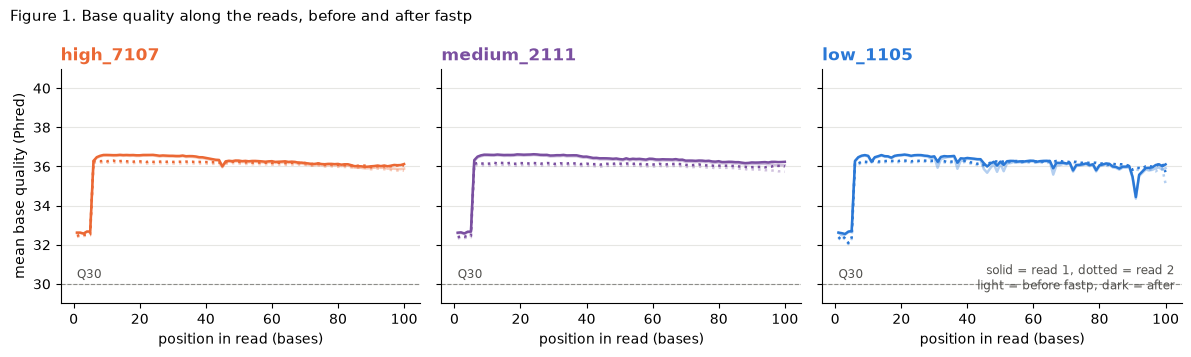

In [45]:
import json
import matplotlib.pyplot as plt

SAMPLES = ["high_7107", "medium_2111", "low_1105"]
COL = {"high_7107": "#eb6834", "medium_2111": "#7a4fa0", "low_1105": "#2a78d6"}      # High = orange, Medium = purple, Low = blue
GREY = "#8d8d89"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.facecolor": "white", "figure.facecolor": "white"})

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
low = 40
for ax, s in zip(axes, SAMPLES):
    j = json.load(open(f"results/trim/{s}.fastp.json"))
    for r, ls in (("read1", "-"), ("read2", ":")):
        for when, alpha in (("before", 0.35), ("after", 1.0)):
            q = j[f"{r}_{when}_filtering"]["quality_curves"]["mean"]
            low = min(low, min(q))
            ax.plot(range(1, len(q) + 1), q, ls, color=COL[s], alpha=alpha, lw=1.8)
    ax.axhline(30, color=GREY, lw=0.8, ls="--")
    ax.text(1, 30.3, "Q30", fontsize=8.5, color="#52514e")
    ax.set_title(s, loc="left", fontweight="bold", color=COL[s])
    ax.set_xlabel("position in read (bases)")
    ax.grid(axis="y", color="#e6e6e3", lw=0.8)
axes[0].set_ylim(min(int(low), 30) - 1, 41)
axes[0].set_ylabel("mean base quality (Phred)")
axes[2].text(0.98, 0.06, "solid = read 1, dotted = read 2\nlight = before fastp, dark = after", transform=axes[2].transAxes, ha="right", fontsize=8.5, color="#52514e")
fig.suptitle("Figure 1. Base quality along the reads, before and after fastp", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 2 - what happened to the reads?** Left: HISAT2 (how many read pairs aligned). Right: featureCounts (how many alignments could be given to a gene).

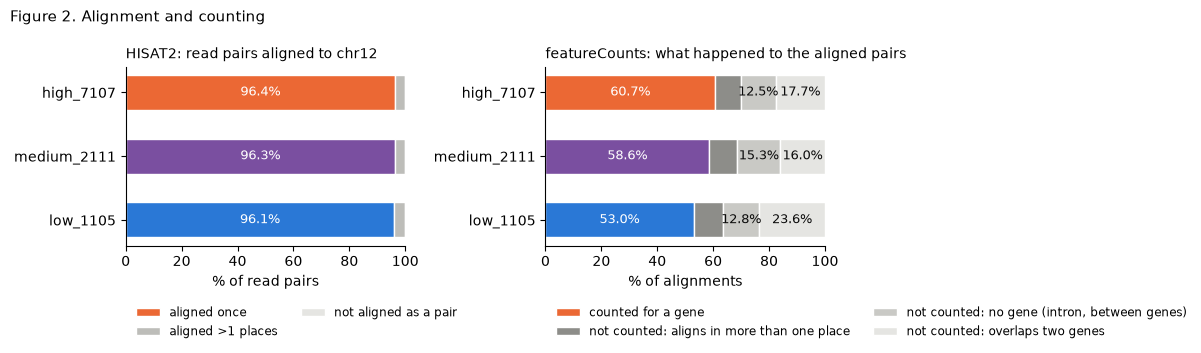

In [46]:
import re

def hisat2(path):
    t = open(path).read()
    n = lambda pat: int(re.search(pat, t).group(1))
    total = n(r"(\d+) reads; of these")
    zero  = n(r"(\d+) \([\d.]+%\) aligned concordantly 0 times")
    one   = n(r"(\d+) \([\d.]+%\) aligned concordantly exactly 1 time")
    many  = n(r"(\d+) \([\d.]+%\) aligned concordantly >1 times")
    return total, [("aligned once", one), ("aligned >1 places", many), ("not aligned as a pair", zero)]

def fcounts(path):
    rows = [l.rstrip("\n").split("\t") for l in open(path)][1:]
    return {r[0]: [int(x) for x in r[1:]] for r in rows}

fc = fcounts("results/counts/counts.txt.summary")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
cols = ["#3a3a38", "#9a9a96", "#d7d7d3"]
for k, s in enumerate(SAMPLES):
    y = 2 - k
    total, parts = hisat2(f"results/align/{s}.hisat2.log")
    left = 0
    for (lab, v), c in zip(parts, [COL[s], "#bdbdb9", "#e5e5e2"]):
        axes[0].barh(y, v / total * 100, left=left, color=c, edgecolor="white", height=0.55, label=lab if k == 0 else None)
        if v / total > 0.12: axes[0].text(left + v / total * 50, y, f"{v / total * 100:.1f}%", ha="center", va="center", color="white" if c == COL[s] else "#0b0b0b", fontsize=9)
        left += v / total * 100
    tot = sum(fc[x][k] for x in fc)
    left = 0
    for lab, c, name in (("Assigned", COL[s], "counted for a gene"), ("Unassigned_MultiMapping", "#8d8d89", "not counted: aligns in more than one place"),
                         ("Unassigned_NoFeatures", "#c9c9c5", "not counted: no gene (intron, between genes)"), ("Unassigned_Ambiguity", "#e5e5e2", "not counted: overlaps two genes")):
        v = fc.get(lab, [0] * len(SAMPLES))[k]
        axes[1].barh(y, v / tot * 100, left=left, color=c, edgecolor="white", height=0.55, label=name if k == 0 else None)
        if v / tot > 0.12: axes[1].text(left + v / tot * 50, y, f"{v / tot * 100:.1f}%", ha="center", va="center", color="white" if c in (COL[s], "#8d8d89") else "#0b0b0b", fontsize=9)
        left += v / tot * 100
for ax, t in zip(axes, ["HISAT2: read pairs aligned to chr12", "featureCounts: what happened to the aligned pairs"]):
    ax.set_yticks([2, 1, 0]); ax.set_yticklabels(SAMPLES); ax.set_xlim(0, 100); ax.set_xlabel("% of read pairs" if ax is axes[0] else "% of alignments")
    ax.set_title(t, loc="left", fontsize=10); ax.legend(loc="upper left", bbox_to_anchor=(0, -0.28), ncol=2, frameon=False, fontsize=8.5)
fig.suptitle("Figure 2. Alignment and counting", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 3 - the same tissue in three animals, gene by gene.** Every dot is one gene; position = counts per million (log scale). All three samples are **liver**, so the genes lie close to the diagonal (equal expression); *r* is the Pearson correlation of the two columns.

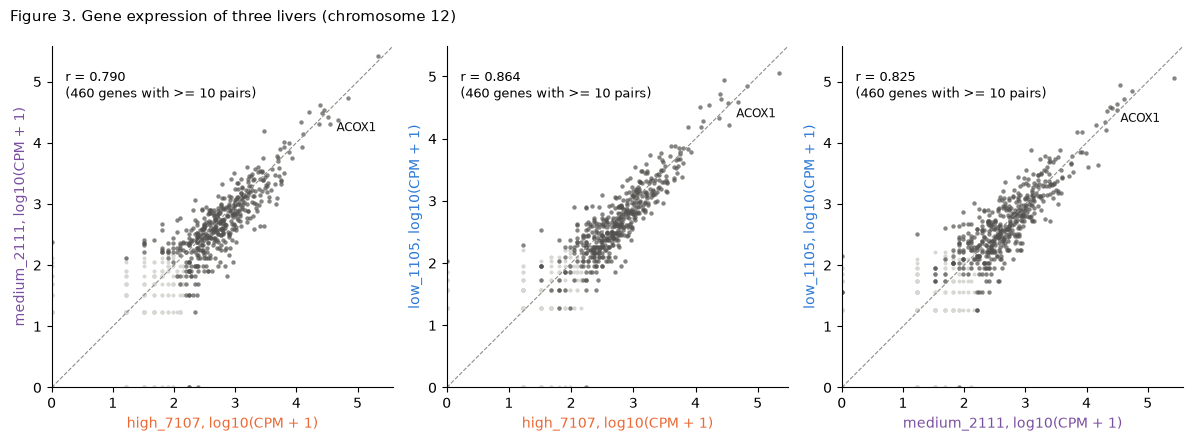

In [47]:
import numpy as np, pandas as pd

cpm = pd.read_csv("results/gene_cpm_annotated.tsv", sep="\t", keep_default_na=False)
cnt = pd.read_csv("results/gene_count_matrix_annotated.tsv", sep="\t", keep_default_na=False)     # same genes, same order, raw counts
expressed = (cnt[SAMPLES] >= 10).any(axis=1)                                                         # genes with at least 10 read pairs in some sample
L = np.log10(cpm[SAMPLES] + 1)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (a, b) in zip(axes, [("high_7107", "medium_2111"), ("high_7107", "low_1105"), ("medium_2111", "low_1105")]):
    ax.scatter(L[a][~expressed], L[b][~expressed], s=8, color="#d7d7d3", lw=0)
    ax.scatter(L[a][expressed], L[b][expressed], s=10, color="#52514e", lw=0, alpha=0.7)
    lim = max(L[a].max(), L[b].max()) + 0.15
    ax.plot([0, lim], [0, lim], color=GREY, lw=0.8, ls="--")
    r = np.corrcoef(L[a][expressed], L[b][expressed])[0, 1]
    ax.text(0.04, 0.93, f"r = {r:.3f}\n({expressed.sum()} genes with >= 10 pairs)", transform=ax.transAxes, va="top", fontsize=9)
    for name in ("ACOX1",):
        h = cpm[cpm.gene_name == name]
        if len(h): ax.annotate(name, (L[a][h.index[0]], L[b][h.index[0]]), xytext=(6, -10), textcoords="offset points", fontsize=8.5, color="#0b0b0b")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
    ax.set_xlabel(f"{a}, log10(CPM + 1)", color=COL[a]); ax.set_ylabel(f"{b}, log10(CPM + 1)", color=COL[b])
fig.suptitle("Figure 3. Gene expression of three livers (chromosome 12)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 4 - the most-counted genes of each sample** (raw counts of read pairs). A few genes take a big share of all reads.

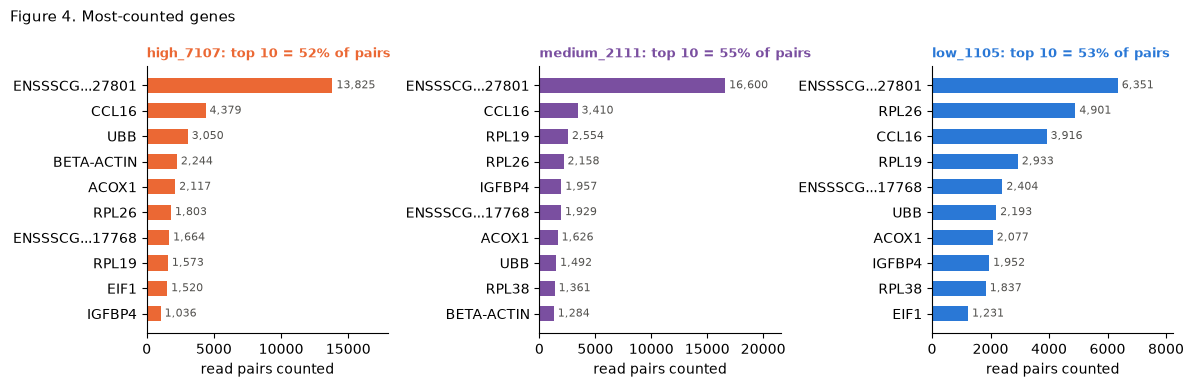

In [48]:
ann = pd.read_csv("results/gene_count_matrix_annotated.tsv", sep="\t", keep_default_na=False)
ann["label"] = ann.gene_name.where(~ann.gene_name.str.startswith("ENSSSCG"), "ENSSSCG..." + ann.gene_name.str[-5:])     # genes without a symbol: shortened Ensembl ID
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, s in zip(axes, SAMPLES):
    top = ann.nlargest(10, s).iloc[::-1]
    ax.barh(top.label, top[s], color=COL[s], height=0.6)
    for y, v in enumerate(top[s]): ax.text(v, y, f" {v:,}", va="center", fontsize=8, color="#52514e")
    share = top[s].sum() / ann[s].sum() * 100
    ax.set_title(f"{s}: top 10 = {share:.0f}% of pairs", loc="left", fontsize=9.5, color=COL[s], fontweight="bold")
    ax.set_xlim(0, top[s].max() * 1.3); ax.set_xlabel("read pairs counted")
fig.suptitle("Figure 4. Most-counted genes", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 5 - where do the reads fall on the chromosome?** Read pairs counted per 1 Mb of chromosome 12 (gene start used as the position), one panel per sample.

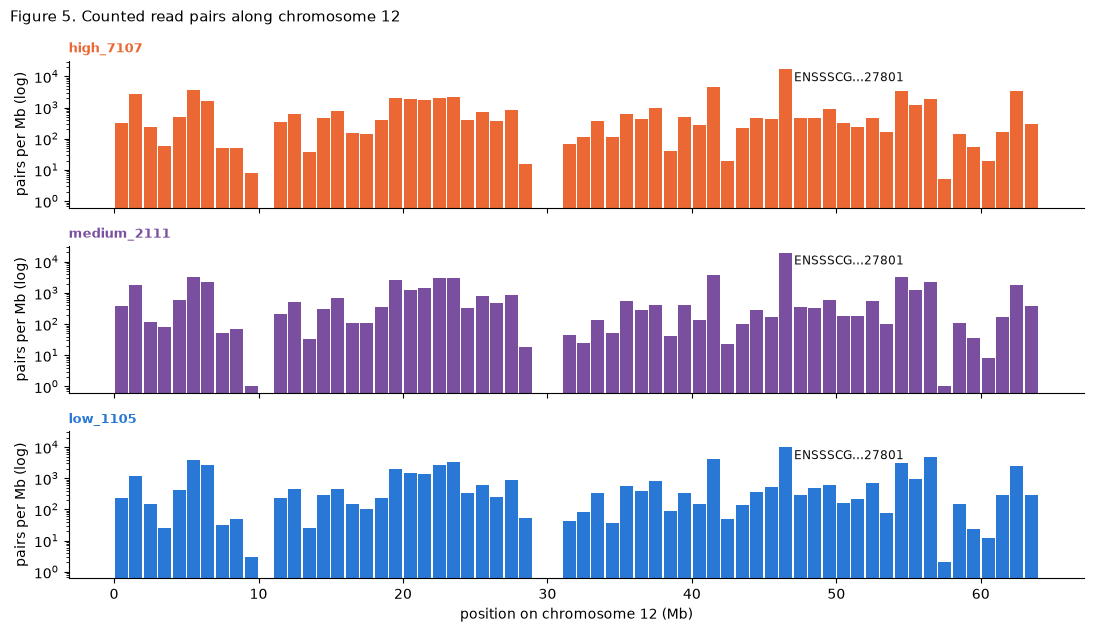

In [49]:
raw = pd.read_csv("results/counts/counts.txt", sep="\t", comment="#", keep_default_na=False)
raw["pos"] = raw["Start"].astype(str).str.split(";").str[0].astype(int)
bins = np.arange(0, raw.pos.max() + 1_000_000, 1_000_000)
fig, axes = plt.subplots(3, 1, figsize=(11, 6.4), sharex=True, sharey=True)
for ax, s in zip(axes, SAMPLES):
    h, _ = np.histogram(raw.pos, bins=bins, weights=raw[f"results/align/{s}.bam"])
    ax.bar(bins[:-1] / 1e6 + 0.5, h, width=0.9, color=COL[s])
    top = raw.loc[raw[f"results/align/{s}.bam"].idxmax()]
    nm = top["gene_name"] if top["gene_name"] != "NA" else "ENSSSCG..." + top["Geneid"][-5:]
    ax.annotate(f"{nm}", (top["pos"] / 1e6, h[min(int(top["pos"] // 1_000_000), len(h) - 1)]), xytext=(6, -2), textcoords="offset points", fontsize=8.5, va="top", color="#0b0b0b")
    ax.set_yscale("log"); ax.set_ylabel("pairs per Mb (log)"); ax.set_title(s, loc="left", fontsize=9.5, color=COL[s], fontweight="bold")
axes[-1].set_xlabel("position on chromosome 12 (Mb)")
fig.suptitle("Figure 5. Counted read pairs along chromosome 12", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

# PART D - Wrap-up

## What did we make?

In [50]:
%%bash
ls -lh results
du -sh results/*  | sort -h


$ ls -lh results
total 168K
drwxr-xr-x 2 root root 4.0K Oct 28 18:11 align
drwxr-xr-x 2 root root 4.0K Oct 28 18:11 counts
-rw-r--r-- 1 root root  30K Oct 28 18:11 gene_count_matrix.tsv
-rw-r--r-- 1 root root  46K Oct 28 18:11 gene_count_matrix_annotated.tsv
-rw-r--r-- 1 root root  55K Oct 28 18:11 gene_cpm_annotated.tsv
drwxr-xr-x 3 root root 4.0K Oct 28 18:11 multiqc_final
drwxr-xr-x 3 root root 4.0K Oct 28 18:09 multiqc_raw
drwxr-xr-x 3 root root 4.0K Oct 28 18:10 multiqc_trim
drwxr-xr-x 8 root root 4.0K Oct 28 18:09 qc_raw
drwxr-xr-x 8 root root 4.0K Oct 28 18:10 qc_trim
drwxr-xr-x 2 root root 4.0K Oct 28 18:09 trim

$ du -sh results/*

$ sort -h
32K	results/gene_count_matrix.tsv
48K	results/gene_count_matrix_annotated.tsv
56K	results/gene_cpm_annotated.tsv
1.2M	results/counts
3.2M	results/multiqc_raw
5.6M	results/multiqc_trim
6.5M	results/multiqc_final
6.7M	results/qc_raw
6.8M	results/qc_trim
23M	results/align
27M	results/trim


`results/gene_count_matrix.tsv` is the file you carry to the next step. Optional: download all results as one zip (reports, BAM files, count tables).

In [51]:
import shutil
zipfile = shutil.make_archive(os.path.join(os.path.dirname(WORK), "RNAseq_pig_results"), "zip", WORK, "results")
print(zipfile, f"{os.path.getsize(zipfile)/1e6:.1f} MB")
try:
    from google.colab import files
    files.download(zipfile)
except ImportError:
    print("(not in Colab: the zip is in the folder above)")

/content/RNAseq_pig_results.zip 58.7 MB
(not in Colab: the zip is in the folder above)


## Questions
1. How many read pairs are in each FASTQ file, and how many survived fastp? Which kind of read was removed most often in low_1105 (hint: *too many N*)?
2. Which FastQC modules fail for these RNA-seq reads? Why is *Per base N content* a FAIL before trimming and a PASS after (hint: position 100)?
3. HISAT2 reports an alignment rate above 99.9 % here. Why is this too good to be true for a real experiment?
4. In step 13, what did the three `-s` settings give, and what does it tell you about the library? What would have happened with the wrong stranded setting?
5. The three samples have different numbers of counted read pairs, and genes have different lengths. Why can you not compare raw counts of one gene between two columns directly? (CPM corrects only one of the two.)
6. One gene without a name (`ENSSSCG00000027801`) takes 11-27 % of all counted pairs, and about one pair in five is *ambiguous*. What can go wrong in an analysis when the annotation has a gene model like this?
7. *NAGS* has about 4 times more read pairs in medium_2111 than in the other two samples. Can you say that *NAGS* is higher in the Medium group? Why not?

## Where to go next
* **Replicates are needed for statistics.** This matrix has one animal per group - enough to learn the pipeline, not to test boar taint. The Day 2 R tutorials use the counts of **all nine boars** (three per group) from the full data: start there with **DESeq2** (differential expression), then volcano plots, PCA, pathways and WGCNA.
* **All the samples:** the study has 96 runs (48 boars x liver and testis). Run the same commands for every sample in a loop (`for s in ...`) and give featureCounts all the BAM files at once.
* **Whole genome:** replace chromosome 12 by the whole Sscrofa11.1 genome (use a pre-built HISAT2 or STAR index, 8-32 GB RAM).
* **Other ways to count:** alignment-free quantification (Salmon, kallisto) skips steps 9-14 and counts straight from the reads.

## Data sources and tools
* Reads: GEO **GSE113316** / ENA **PRJNA451072** (Drag, Skinkyte-Juskiene, Do, Kogelman, Kadarmideen; Danish Landrace boars, liver, Illumina HiSeq 2500), runs SRR7041911 (animal 7107, High), SRR7041924 (animal 2111, Medium), SRR7041939 (animal 1105, Low); the first 100,000 read pairs that align to chromosome 12, unchanged. See `data/SOURCES.md` and `data/make_subset.sh`.
* Reference and annotation: Ensembl release 79, *Sus scrofa* Sscrofa10.2, chromosome 12.
* Tools: FastQC 0.13.0, MultiQC 1.35, fastp 1.4.0, HISAT2 2.2.3, samtools 1.24, Subread (featureCounts) 2.1.1.